# Lab 4 - Transfer Learning CNNs

Ava Everett (49136678)

Jay Lu (49200794)

## Introduction
In this lab, you will select a prediction task to perform on an image dataset, transfer learn from a convolutional neural network architecture and evaluate performance. If any part of the assignment is not clear, ask the instructor to clarify. This report is worth 10% of the final grade. Please upload a report (one per team) with all code used, visualizations, and text in a rendered Jupyter notebook. Any visualizations that cannot be embedded in the notebook, please provide screenshots of the output. The results should be reproducible using your report. Please carefully describe every assumption and every step in your report.

Dataset Selection. Select a dataset for classification of images. That is, the dataset must be image data and should be multi-class (not binary). In terms of generalization performance, it is helpful to have a medium-sized dataset of identically sized images. These datasets can get quite computational, so it is recommended to choose a dataset with fewer than 50 classes and modest image resolutions. You may also resize the images to be smaller, if desired. You are NOT allowed to use MNIST, Fashion MNIST, the sklearn digits dataset, any of the CIFAR datasets, or the Tiny ImageNet dataset. Be sure to provide a link or citation to your chosen dataset.

Chosen dataset: https://www.kaggle.com/datasets/divyanshusingh369/complete-pokemon-library-32k-images-and-csv
****

## Evaluation Strategy
Prompt an LLM to suggest evaluation metrics appropriate for your application. The prompt should encourage the LLM to discuss:
- class imbalance,
- business considerations,
- appropriate evaluation metrics,
- deployment considerations.

When using the LLM, please provide: your prompt, the LLM response, identify at least two weaknesses or generic statements, and provide your own refined evaluation strategy. These final two items are crucial. The LLM output is likely to provide generic non-application specific reasoning for some evaluation criteria. It is your task to fix any aspects of the evaluation criteria that are inappropriate or overly generic.

**Prompt:** I am doing a lab where I will conduct a prediction task to perform on an image dataset, transfer learn from a convolutional neural network architecture, and evaluate performance. I have selected this Pokémon dataset (https://www.kaggle.com/datasets/divyanshusingh369/complete-pokemon-library-32k-images-and-csv) that has details about different Pokémon such as type and species. I eventually want to be able to differentiate images of Pokémon by aspects such as their type. This information may be useful to artists and creative directors in designing new Pokémon by identifying shared qualities that certain types of Pokémon may have. 

I want to reduce computational power required of my computer. Please guide me on how to reduce image sizes in Python. Additionally, the .csv file is separate from the image files, but I want to combine the two into one dataset. Please guide me on how to do that as well. 

Please discuss class imbalances, additional business considerations, appropriate evaluation metrics, and deployment considerations.

*I attached Lab4.ipynb*

**Agent used:** Claude Sonnet 5.5 

**Output:** 
# Pokémon type classification: data prep and evaluation planning

I haven't opened the Kaggle page, so the column names below (`image_path`, `type1`, etc.) are placeholders. Run `df.columns` and `df.head()` first and adjust.

## 1. Shrinking images

Resize once, save to a new folder, and train from the small copies. That is much cheaper than resizing every image on every epoch. For transfer learning, 128×128 is a good low-compute choice, and 224×224 is the pretrained models' native size if your machine can handle it.

```python
from pathlib import Path
from PIL import Image
from tqdm import tqdm

SRC = Path("pokemon_images")        # original images
DST = Path("pokemon_128")           # resized copies
SIZE = (128, 128)
DST.mkdir(exist_ok=True)

def resize_image(src_path, dst_path, size=SIZE):
    img = Image.open(src_path)
    # Many sprites/artwork are PNGs with transparency; flatten onto white
    if img.mode in ("RGBA", "LA", "P"):
        img = img.convert("RGBA")
        bg = Image.new("RGB", img.size, (255, 255, 255))
        bg.paste(img, mask=img.split()[-1])
        img = bg
    else:
        img = img.convert("RGB")
    img = img.resize(size, Image.LANCZOS)
    img.save(dst_path, quality=95)

for p in tqdm(list(SRC.rglob("*"))):
    if p.suffix.lower() in {".png", ".jpg", ".jpeg"}:
        resize_image(p, DST / (p.stem + ".png"))
```

Notes:
- Compositing on white matters: a naive `.convert("RGB")` turns transparent pixels black, which would be a systematic artifact in your data.
- If images aren't square, pad to square before resizing, or the Pokémon will be stretched.
- Further savings: use a small architecture (MobileNetV3, EfficientNet-B0), a smaller batch size, and mixed precision (`torch.autocast`) if you have a GPU.

## 2. Combining the CSV with the images

Build a DataFrame with one row per image and a column pointing to its file path. That is the "single dataset".

```python
import pandas as pd

df = pd.read_csv("pokemon.csv")
print(df.columns.tolist())

# Build the path from whatever links the CSV row to the file (id, name, filename...)
df["image_path"] = df["filename"].apply(lambda f: str(DST / (Path(f).stem + ".png")))

# Keep only rows whose image actually exists
exists = df["image_path"].apply(lambda p: Path(p).exists())
print(f"Missing images: {(~exists).sum()}")
df = df[exists].reset_index(drop=True)

# Encode labels
classes = sorted(df["type1"].unique())
df["label"] = df["type1"].map({c: i for i, c in enumerate(classes)})
df.to_csv("pokemon_combined.csv", index=False)
```

Then a PyTorch `Dataset` reads from the DataFrame:

```python
from torch.utils.data import Dataset

class PokemonDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df, self.transform = df.reset_index(drop=True), transform
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(row["image_path"]).convert("RGB")
        if self.transform: img = self.transform(img)
        return img, row["label"]
```

Decide early whether to predict primary type only (single-label, about 18 classes) or both types (multi-label). The lab requires multi-class rather than binary, and primary type is the simplest fit. You could treat dual typing as an extension.

## 3. Class imbalance

- **Expect skew.** Types like Water and Normal have far more Pokémon than Flying, Fairy, or Ice. Run `df["type1"].value_counts()` and plot it. If you use primary type, Flying will be extremely rare.
- **Hidden duplicates.** A dataset of ~32k images likely has many images per species (forms, shiny variants, different art styles). That inflates both the apparent size and the imbalance, because a type with one prolific species looks bigger than it really is. Check images per species as well as per type.
- **Mitigations:** class-weighted cross-entropy, a weighted sampler, or merging/dropping classes with very few samples. Avoid heavy oversampling of tiny classes, since the model will memorize those few images. Use stratified splits so rare classes appear in validation and test.
- **Split by species, not by image.** If variants of the same Pokémon land in both train and test, you leak information and inflate your scores. Use `GroupShuffleSplit` or `StratifiedGroupKFold` with species as the group. This also fits your "realistic deployment" justification in the Splitting Criteria section.

## 4. Business considerations

- **Use case:** artists and creative directors want to learn which visual traits go with each type, not just a label. A classifier is only a means to that end. Pair it with Grad-CAM or saliency maps to show which regions drive predictions.
- **Shortcut risk:** type correlates heavily with color (Water is blue, Fire is red/orange). A model could reach decent accuracy on color alone, which tells designers nothing new. Consider a color-only baseline (for example, mean-color features with logistic regression) to see how much the CNN adds. This is a good "exceptional work" idea.
- **Ambiguity is inherent:** some types are visually ambiguous (Normal, Psychic) and dual types blur the signal. Errors between plausible look-alikes are less costly than errors between unrelated types, so a confusion matrix matters more than a single accuracy number.
- **Cost of errors:** a wrong prediction here costs a designer a bad suggestion, not safety or money. That favors reporting top-3 predictions rather than forcing one hard label.
- **Other considerations:** Pokémon art is copyrighted by Nintendo/Game Freak/The Pokémon Company, so it's fine for a class project but not a deployable commercial product without licensing review.

## 5. Evaluation metrics

| Metric | Why |
|---|---|
| **Macro-F1** (primary) | Weights every type equally, so rare types count as much as Water. Plain accuracy would reward ignoring small classes. |
| **Per-class precision/recall** | Shows which types the model fails on. |
| **Top-3 accuracy** | Matches the "suggestion" use case and the real ambiguity between types. |
| **Confusion matrix** | Reveals which types get confused, which is itself useful for designers. |
| **Weighted-F1 / accuracy** | Reported for context only. |
| **Calibration (ECE)** | Useful if you show confidence scores to users. |

With only four trained models, use McNemar's test on the shared test set, or bootstrap confidence intervals on macro-F1, for the "statistical comparison" requirement.

## 6. Deployment considerations

- **Domain shift:** the model trains on official artwork but would be used on concept sketches, fan art, or AI-generated drafts, which look different. Your test set only measures performance on in-distribution official art, so say so in your report.
- **Time/generation drift:** new Pokémon generations introduce new art styles and type combinations, so the model needs periodic retraining.
- **Inference cost:** a small model at 128–224 px runs on CPU in a design tool. This is another reason to prefer MobileNet or EfficientNet-B0.
- **Presentation:** show probabilities and explanations (heatmaps), not just a label, and make clear the output is a statistical association, not a rule about how types must look.
- **Preprocessing parity:** the deployed pipeline must use the same resize, white-background flattening, and normalization as training.

## For your notebook

The Evaluation Strategy section asks for your prompt, the LLM output, at least two weaknesses or generic statements, and your refined strategy. You can use this response as that LLM output, but you must write the critique yourself. Candidate weaknesses to check:
- I assumed an unseen dataset structure, including column names and the presence of species duplicates, and haven't verified either.
- The "business considerations" are partly generic and rest on assumptions about how artists work.
- The shortcut and color-baseline point is a hypothesis you should test, not a fact.

Once you've loaded the CSV, send me the output of `df.columns` and `df["type1"].value_counts()` and I can tighten the merge code and the imbalance strategy to your actual data.
****
End of output

**Resizing images**

In [1]:
import re, unicodedata
from pathlib import Path
import pandas as pd
from PIL import Image
from tqdm import tqdm

SRC = Path("Pokemon/Pokemon Images DB/") # original image file path
DST = Path("pokemon_128")                # resized copies all combined into one folder
SIZE = (128, 128)
DST.mkdir(exist_ok=True)

def norm(s): # normalize file names
    s = str(s).replace("♀", "f").replace("♂", "m")
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]", "", s.lower())

def resize_image(src_path, dst_path, size=SIZE): # resize images to 128x128
    img = Image.open(src_path)
    # Many sprites/artwork are PNGs with transparency; flatten onto white
    if img.mode in ("RGBA", "LA", "P"):
        img = img.convert("RGBA")
        bg = Image.new("RGB", img.size, (255, 255, 255))
        bg.paste(img, mask=img.split()[-1])
        img = bg
    else:
        img = img.convert("RGB")
    img = img.resize(size, Image.LANCZOS)
    img.save(dst_path, quality=95)

def resize_square(src, dst, size=SIZE):
    img = Image.open(src)
    # Flatten any transparency onto white
    if img.mode in ("RGBA", "LA", "P"):
        img = img.convert("RGBA")
        bg = Image.new("RGB", img.size, (255, 255, 255))
        bg.paste(img, mask=img.split()[-1])
        img = bg
    else:
        img = img.convert("RGB")
    # Pad to square on white so the Pokémon isn't stretched
    w, h = img.size
    side = max(w, h)
    canvas = Image.new("RGB", (side, side), (255, 255, 255))
    canvas.paste(img, ((side - w) // 2, (side - h) // 2))
    canvas.resize((size, size), Image.LANCZOS).save(dst)
    
def image_to_folder(): # add images to new destination folder DST
    for p in tqdm(list(SRC.rglob("*"))):
        if p.suffix.lower() in {".png"}:
            resize_image(p, DST / (p.stem + ".png"))

In [2]:
# Remove the files in the folder
from pathlib import Path
import shutil

folder = Path("pokemon_128")

for item in folder.iterdir():
    if item.is_symlink() or item.is_file():
        item.unlink()
    else:
        shutil.rmtree(item)

In [3]:
image_to_folder() # put official art into pokemon_128

# SRC = Path("Pokemon/Pokemon Dataset/") # file path for in game sprites
# image_to_folder() # put sprites into pokemon_128

100%|██████████| 3561/3561 [02:13<00:00, 26.69it/s]  


**Read the .csv file**

In [4]:
import pandas as pd
import re, unicodedata
import numpy as np

# Show columns in the dataset
df = pd.read_csv("pokemonDB_dataset.csv")
print(df.columns.tolist())

['Pokemon', 'Type', 'Species', 'Height', 'Weight', 'Abilities', 'EV Yield', 'Catch Rate', 'Base Friendship', 'Base Exp', 'Growth Rate', 'Egg Groups', 'Gender', 'Egg Cycles', 'HP Base', 'HP Min', 'HP Max', 'Attack Base', 'Attack Min', 'Attack Max', 'Defense Base', 'Defense Min', 'Defense Max', 'Special Attack Base', 'Special Attack Min', 'Special Attack Max', 'Special Defense Base', 'Special Defense Min', 'Special Defense Max', 'Speed Base', 'Speed Min', 'Speed Max']


**Add photos to dataframe**

In [5]:
import re, unicodedata
from pathlib import Path
import pandas as pd
from PIL import Image
from tqdm import tqdm

SRC = Path("Pokemon/Pokemon Images DB/") # original image file path
DST = Path("pokemon_128")                # resized copies all combined into one folder
DST.mkdir(exist_ok=True)
SIZE = 128

def norm(s):
    s = str(s).replace("♀", "f").replace("♂", "m")
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]", "", s.lower())

def resize_square(src, dst, size=SIZE):
    img = Image.open(src)
    # Flatten any transparency onto white
    if img.mode in ("RGBA", "LA", "P"):
        img = img.convert("RGBA")
        bg = Image.new("RGB", img.size, (255, 255, 255))
        bg.paste(img, mask=img.split()[-1])
        img = bg
    else:
        img = img.convert("RGB")
    # Pad to square on white so the Pokémon isn't stretched
    w, h = img.size
    side = max(w, h)
    canvas = Image.new("RGB", (side, side), (255, 255, 255))
    canvas.paste(img, ((side - w) // 2, (side - h) // 2))
    canvas.resize((size, size), Image.LANCZOS).save(dst)

# 1. Resize the white-background image in each folder, record the paths
rows = []
for folder in tqdm(sorted(p for p in SRC.iterdir() if p.is_dir())):
    white = [p for p in folder.glob("*.png") if not p.stem.endswith("_new")]
    if not white:
        print("No white-background image in:", folder.name)
        continue
    out = DST / f"{folder.name}.png"
    resize_square(white[0], out)
    rows.append({"folder": folder.name, "key": norm(folder.name), "image_path": str(out)})

img_df = pd.DataFrame(rows)

# 2. Merge with the CSV
df = pd.read_csv("pokemonDB_dataset.csv")
df["key"] = df["Pokemon"].apply(norm)

merged = df.merge(img_df, on="key", how="inner")

# 3. Check what failed to match
print("CSV rows without an image:", sorted(set(df["key"]) - set(img_df["key"]))[:30])
print("Images without a CSV row:", sorted(set(img_df["key"]) - set(df["key"]))[:30])
print("Duplicate keys:", merged["key"].duplicated().sum())

merged.to_csv("pokemon_combined.csv", index=False)

100%|██████████| 1187/1187 [01:19<00:00, 14.98it/s]


CSV rows without an image: ['ashgreninja', 'blackkyurem', 'castformrainyform', 'castformsnowyform', 'castformsunnyform', 'dawnwingsnecrozma', 'dudunsparcethreesegmentform', 'duskmanenecrozma', 'eternatuseternamax', 'fanrotom', 'frostrotom', 'gougingfire', 'gourgeistaveragesize', 'gourgeistlargesize', 'gourgeistsmallsize', 'gourgeistsupersize', 'heatrotom', 'hoopaconfined', 'hoopaunbound', 'hydrapple', 'ironboulder', 'mausholdfamilyofthree', 'mowrotom', 'nidoranffemalenidoranf', 'nidoranmmalenidoranm', 'ogerponcornerstonemask', 'ogerponhearthflamemask', 'ogerponwellspringmask', 'owntemporockruff', 'partnereevee']
Images without a CSV row: ['eeveepartnereevee', 'greninjaashgreninja', 'hoopahoopaconfined', 'hoopahoopaunbound', 'kyuremblackkyurem', 'kyuremwhitekyurem', 'necrozmadawnwingsnecrozma', 'necrozmaduskmanenecrozma', 'necrozmaultranecrozma', 'nidoranf', 'nidoranm', 'pikachupartnerpikachu', 'rotomfanrotom', 'rotomfrostrotom', 'rotomheatrotom', 'rotommowrotom', 'rotomwashrotom']
Dupl

In [6]:
merged

,Pokemon,Type,Species,Height,Weight,Abilities,EV Yield,Catch Rate,Base Friendship,Base Exp,...,Special Attack Max,Special Defense Base,Special Defense Min,Special Defense Max,Speed Base,Speed Min,Speed Max,key,folder,image_path
0,Abomasnow,"Grass, Ice",Frost Tree Pokémon,2.2 m (7′03″),135.5 kg (298.7 lbs),"1. Snow Warning, Soundproof (hidden ability)","1 Attack, 1 Sp. Atk","60 (7.8% with PokéBall, full HP)",50 (normal),173,...,311,85,157,295,60,112,240,abomasnow,Abomasnow,pokemon_128\Abomasnow.png
1,Mega Abomasnow,"Grass, Ice",Frost Tree Pokémon,2.7 m (8′10″),185.0 kg (407.9 lbs),1. Snow Warning,"1 Attack, 1 Sp. Atk","60 (7.8% with PokéBall, full HP)",50 (normal),208,...,399,105,193,339,30,58,174,megaabomasnow,Mega Abomasnow,pokemon_128\Mega Abomasnow.png
2,Abra,Psychic,Psi Pokémon,0.9 m (2′11″),19.5 kg (43.0 lbs),"1. Synchronize, 2. Inner Focus, Magic Guard (h...",1 Sp. Atk,"200 (26.1% with PokéBall, full HP)",50 (normal),62,...,339,55,103,229,90,166,306,abra,Abra,pokemon_128\Abra.png
3,Absol,Dark,Disaster Pokémon,1.2 m (3′11″),47.0 kg (103.6 lbs),"1. Pressure, 2. Super Luck, Justified (hidden ...",2 Attack,"30 (3.9% with PokéBall, full HP)",35 (lower than normal),163,...,273,60,112,240,75,139,273,absol,Absol,pokemon_128\Absol.png
4,Mega Absol,Dark,Disaster Pokémon,1.2 m (3′11″),49.0 kg (108.0 lbs),1. Magic Bounce,2 Attack,"30 (3.9% with PokéBall, full HP)",35 (lower than normal),198,...,361,60,112,240,115,211,361,megaabsol,Mega Absol,pokemon_128\Mega Absol.png
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1165,Zubat,"Poison, Flying",Bat Pokémon,0.8 m (2′07″),7.5 kg (16.5 lbs),"1. Inner Focus, Infiltrator (hidden ability)",1 Speed,"255 (33.3% with PokéBall, full HP)",50 (normal),49,...,174,40,76,196,55,103,229,zubat,Zubat,pokemon_128\Zubat.png
1166,Zweilous,"Dark, Dragon",Hostile Pokémon,1.4 m (4′07″),50.0 kg (110.2 lbs),1. Hustle,2 Attack,"45 (5.9% with PokéBall, full HP)",35 (lower than normal),147,...,251,70,130,262,58,108,236,zweilous,Zweilous,pokemon_128\Zweilous.png
1167,Zygarde 50% Forme,"Dragon, Ground",Order Pokémon,5.0 m (16′05″),305.0 kg (672.4 lbs),"1. Aura Break, 2. Power Construct",3 HP,"3 (0.4% with PokéBall, full HP)",0 (lower than normal),270,...,287,95,175,317,95,175,317,zygarde50forme,Zygarde (50% Forme),pokemon_128\Zygarde (50% Forme).png
1168,Zygarde 10% Forme,"Dragon, Ground",Order Pokémon,1.2 m (3′11″),33.5 kg (73.9 lbs),"1. Aura Break, 2. Power Construct",3 HP,"3 (0.4% with PokéBall, full HP)",0 (lower than normal),219,...,243,85,157,295,115,211,361,zygarde10forme,Zygarde (10% Forme),pokemon_128\Zygarde (10% Forme).png


In [18]:
df = merged

**Convert Growth Rate and Base Friendship to integer values**

In [19]:
print('Unique values in Growth Rate\n')
print(df['Growth Rate'].unique())

print('\n\nUnique values in Base Friendship\n')
print(df['Base Friendship'].unique())

print('\n\nUnique values in Egg Cycles\n')
print(df['Egg Cycles'].unique())

Unique values in Growth Rate

<IntegerArray>
[0, 1, 2, 3, -1, -2]
Length: 6, dtype: Int64


Unique values in Base Friendship

<IntegerArray>
[50, 35, 100, 0, <NA>, 20, 140, 90, 70]
Length: 9, dtype: Int64


Unique values in Egg Cycles

<IntegerArray>
[20, 25, 15, 35, 40, 30, 120, <NA>, 80, 10, 50, 5]
Length: 12, dtype: Int64


In [21]:
# Convert Growth Rate to Int64
df['Growth Rate'] = df['Growth Rate'].replace({'Slow': 0,
                                               'Medium Slow': 1,
                                               'Medium Fast': 2,
                                               'Fast': 3,
                                               'Erratic': -1,
                                               'Fluctuating': -2,
                                               }).astype("Int64")

df['Base Friendship'] = (
    df['Base Friendship']
    .astype("string")
    .replace({'—': pd.NA})
    .str.extract(r"(\d+)", expand = False)
    .astype("Int64")
)

df['Egg Cycles'] = (
    df['Egg Cycles']
    .astype("string")
    .replace({'—':pd.NA})
    .str.extract(r"(\d+)", expand = False)
    .astype("Int64")
)

# Convert Base Exp to Int64 and replace '—' with missing value
df['Base Exp'] = df['Base Exp'].replace({'—': pd.NA,}).astype("Int64")

# Split Gender by 'Male Proportion' and 'Female Proportion'
df["Gender"] = df['Gender'].replace({'Genderless': '0% male, 0% female'})

df[["Male Proportion", "Female Proportion"]] = (
    df["Gender"]
    .str.extract(r"(\d+(?:\.\d+)?)%\s*male,\s*(\d+(?:\.\d+)?)%\s*female")
    .astype(float)
    .div(100)
)

# Extract height in meters
df["Height (m)"] = (
    df["Height"]
    .str.extract(r"(\d+(?:\.\d+)?)\s*m", expand = False)
    .astype(float)
)

# Extract weight in kg
df["Weight (kg)"] = (
    df["Weight"]
    .str.extract(r"(\d+(?:\.\d+)?)\s*kg", expand=False)
    .astype(float)
)

# Extract catch rate %
df["Catch Rate (%)"] = pd.to_numeric(
    df["Catch Rate"].str.extract(r"\((\d+(?:\.\d+)?)%", expand=False),
    errors="coerce"
)

**One-hot encoding for Pokemon types**

In [22]:
from sklearn.preprocessing import MultiLabelBinarizer
import missingno as mn

type_lists = df['Type'].str.split(',').apply(lambda lst: [g.strip() for g in lst])

mlb = MultiLabelBinarizer()
type_encoded = pd.DataFrame(
    mlb.fit_transform(type_lists),
    columns = mlb.classes_,
    index = df.index
)

types_to_keep = ['Bug', 'Dark', 'Dragon', 'Electric', 'Fairy', 'Fighting',
                 'Fire', 'Flying', 'Ghost', 'Grass', 'Ground', 'Ice', 'Normal',
                 'Poison', 'Psychic', 'Rock', 'Steel', 'Water']

type_encoded = type_encoded[[col for col in type_encoded.columns if col in types_to_keep]]

df = pd.concat([df, type_encoded], axis = 1)

In [23]:
df

,Pokemon,Type,Species,Height,Weight,Abilities,EV Yield,Catch Rate,Base Friendship,Base Exp,...,Ghost,Grass,Ground,Ice,Normal,Poison,Psychic,Rock,Steel,Water
0,Abomasnow,"Grass, Ice",Frost Tree Pokémon,2.2 m (7′03″),135.5 kg (298.7 lbs),"1. Snow Warning, Soundproof (hidden ability)","1 Attack, 1 Sp. Atk","60 (7.8% with PokéBall, full HP)",50,173,...,0,1,0,1,0,0,0,0,0,0
1,Mega Abomasnow,"Grass, Ice",Frost Tree Pokémon,2.7 m (8′10″),185.0 kg (407.9 lbs),1. Snow Warning,"1 Attack, 1 Sp. Atk","60 (7.8% with PokéBall, full HP)",50,208,...,0,1,0,1,0,0,0,0,0,0
2,Abra,Psychic,Psi Pokémon,0.9 m (2′11″),19.5 kg (43.0 lbs),"1. Synchronize, 2. Inner Focus, Magic Guard (h...",1 Sp. Atk,"200 (26.1% with PokéBall, full HP)",50,62,...,0,0,0,0,0,0,1,0,0,0
3,Absol,Dark,Disaster Pokémon,1.2 m (3′11″),47.0 kg (103.6 lbs),"1. Pressure, 2. Super Luck, Justified (hidden ...",2 Attack,"30 (3.9% with PokéBall, full HP)",35,163,...,0,0,0,0,0,0,0,0,0,0
4,Mega Absol,Dark,Disaster Pokémon,1.2 m (3′11″),49.0 kg (108.0 lbs),1. Magic Bounce,2 Attack,"30 (3.9% with PokéBall, full HP)",35,198,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1165,Zubat,"Poison, Flying",Bat Pokémon,0.8 m (2′07″),7.5 kg (16.5 lbs),"1. Inner Focus, Infiltrator (hidden ability)",1 Speed,"255 (33.3% with PokéBall, full HP)",50,49,...,0,0,0,0,0,1,0,0,0,0
1166,Zweilous,"Dark, Dragon",Hostile Pokémon,1.4 m (4′07″),50.0 kg (110.2 lbs),1. Hustle,2 Attack,"45 (5.9% with PokéBall, full HP)",35,147,...,0,0,0,0,0,0,0,0,0,0
1167,Zygarde 50% Forme,"Dragon, Ground",Order Pokémon,5.0 m (16′05″),305.0 kg (672.4 lbs),"1. Aura Break, 2. Power Construct",3 HP,"3 (0.4% with PokéBall, full HP)",0,270,...,0,0,1,0,0,0,0,0,0,0
1168,Zygarde 10% Forme,"Dragon, Ground",Order Pokémon,1.2 m (3′11″),33.5 kg (73.9 lbs),"1. Aura Break, 2. Power Construct",3 HP,"3 (0.4% with PokéBall, full HP)",0,219,...,0,0,1,0,0,0,0,0,0,0


In [25]:
df.to_csv("pokemon_df.csv", index=False)

****

## Splitting Criteria

Without LLM assistance, justify your train/validation/test methodology. Explain:
- why your splitting strategy reflects realistic deployment,
- whether cross-validation is appropriate,
- how validation data will be used during training.

Because the number of Pokemon per type varies, I have chosen to perform Stratified Group KFold Sampling on the dataset. Because there is an uneven distribution of Pokemon per type, types such as Water are likely to be overrepresented than Flying. Stratification ensures that each type is represented during training. One limitation of this dataset is the fact that there are very few flying types. 

In [ ]:
from sklearn.model_selection import StratifiedGroupKFold

df["type1"] = df["Type"].str.split(",").str[0].str.strip()
print(df["type1"].value_counts())

# Group by Megas and regional variants
df["group"] = df["Pokemon"].str.replace(r"^(Mega|Hisuian|Galarian|Alolan|Paldean)\s+", "", regex=True)\
                           .str.split().str[0]

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, temp_idx = next(sgkf.split(df, df["type1"], groups=df["group"]))
temp = df.iloc[temp_idx]

sgkf2 = StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=42)
val_rel, test_rel = next(sgkf2.split(temp, temp["type1"], groups=temp["group"]))

train_df = df.iloc[train_idx].reset_index(drop=True)
val_df   = temp.iloc[val_rel].reset_index(drop=True)
test_df  = temp.iloc[test_rel].reset_index(drop=True)

type1
Water       148
Normal      126
Grass       108
Bug          91
Psychic      77
Fire         74
Electric     68
Rock         66
Dark         56
Fighting     50
Dragon       47
Poison       46
Ground       46
Steel        45
Ice          42
Ghost        39
Fairy        31
Flying       10
Name: count, dtype: int64


****

## Data Augmentation

When training your CNN, you should use an augmentation pipeline. You may use an LLM to generate augmentation code. Explain why each augmentation is appropriate for your dataset. If using an LLM, identify one augmentation recommendation that you rejected or modified and explain why. Example augmentation include flips, rotations, translations, contrast changes, etc.

Prompt: Please generate augmentation code for the augmentation pipeline to train the CNN. 

Agent Used: Claude Sonnet 5.5

**Output:**
# Augmentation pipeline

This uses the `train_df`, `val_df`, `test_df` and `type1` column your notebook already created, and skips the splitting code. I haven't opened your resized images, so I'm assuming what your resize step produced: 128×128, white background, Pokémon roughly centered.

## Transforms and dataset

```python
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2

IMAGENET_MEAN = [0.485, 0.456, 0.406]   # required for ImageNet-pretrained models
IMAGENET_STD  = [0.229, 0.224, 0.225]

# Random geometric/color steps (operate on PIL images)
aug_steps = [
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandomAffine(
        degrees=15,
        translate=(0.08, 0.08),
        scale=(0.9, 1.1),
        fill=255,                      # white fill to match the background
    ),
    v2.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15, hue=0.0),
]

to_tensor_steps = [
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(IMAGENET_MEAN, IMAGENET_STD),
]

train_transform = v2.Compose(aug_steps + to_tensor_steps)
eval_transform  = v2.Compose(to_tensor_steps)   # no randomness for val/test

TYPE_COLS = ['Bug','Dark','Dragon','Electric','Fairy','Fighting','Fire','Flying',
             'Ghost','Grass','Ground','Ice','Normal','Poison','Psychic','Rock','Steel','Water']
class_to_idx = {c: i for i, c in enumerate(TYPE_COLS)}

class PokemonDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(row["image_path"]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, class_to_idx[row["type1"]]

train_ds = PokemonDataset(train_df, train_transform)
val_ds   = PokemonDataset(val_df,   eval_transform)
test_ds  = PokemonDataset(test_df,  eval_transform)

# num_workers=0 is safest on Windows in a notebook
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=64, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=64, shuffle=False, num_workers=0)
```

## Check it visually

The lab requires validated code, so look at the output before training.

```python
import matplotlib.pyplot as plt
import numpy as np

def show_augmentations(df, idx=0, n=7):
    row = df.iloc[idx]
    img = Image.open(row["image_path"]).convert("RGB")
    aug = v2.Compose(aug_steps)
    fig, axes = plt.subplots(1, n + 1, figsize=(2.2 * (n + 1), 2.6))
    axes[0].imshow(img); axes[0].set_title("original")
    for ax in axes[1:]:
        ax.imshow(aug(img))
    for ax in axes: ax.axis("off")
    plt.suptitle(f'{row["Pokemon"]} ({row["type1"]})')
    plt.show()

show_augmentations(train_df, idx=0)
show_augmentations(train_df, idx=len(train_df) // 2)

# Sanity-check a batch
xb, yb = next(iter(train_loader))
print(xb.shape, xb.dtype, yb[:8])
```

Look for black corners (fill is wrong), cropped limbs, or color shifts that change the apparent type.

## Why each augmentation fits (draft for your notebook)

| Augmentation | Rationale |
|---|---|
| Horizontal flip | Official art faces left or right arbitrarily, and a mirrored Pokémon keeps its type. |
| Rotation ±15° | Mimics pose variation without making the creature unrecognizable. |
| Translation ≤8%, scale 0.9–1.1 | Keeps the model from relying on exact centering or size, which new artwork won't match. |
| Brightness/contrast/saturation ±0.15 | Simulates rendering differences while keeping dominant colors, which carry type information. |
| White `fill=255` | Matches your flattened white background. The default black fill would create an artifact that only appears in augmented training images. |

## Recommendations to reject or modify

You can cite these for the "rejected or modified" requirement, but write your own justification.

- **Hue jitter, modified to 0.** Generic pipelines include it by default, but a hue shift could make a Fire Pokémon look blue while keeping the Fire label, which injects label noise.
- **Vertical flip, rejected.** Upside-down Pokémon never appear in your data or in deployment.
- **Random erasing/cutout, rejected.** It can erase the one feature that signals the type (wings, flames), which is costly with about 1,170 images. You could test it as an ablation.

## Caveats

- Brightness below 1.0 turns the white background slightly gray. At 0.15 it's mild, but check the visualization.
- Augmentation doesn't fix class imbalance. Flying has only 10 primary-type images in your counts, so pair this with class-weighted loss or a weighted sampler.
- The parameter values (15°, 8%, 0.15) are reasonable starting points, not tuned choices. Say so in your critique.
- Your images are 128×128 and the pretrained models used 224. They work at 128, but you can add `v2.Resize(224)` as the first step of both pipelines if accuracy is poor and compute allows.

For the notebook's prompt/agent/output fields, you can use this response as the LLM output. Your critique should cover the assumptions I made about image appearance and the untuned parameters.
****

End of output

In [29]:
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2

IMAGENET_MEAN = [0.485, 0.456, 0.406]   # required for ImageNet-pretrained models
IMAGENET_STD  = [0.229, 0.224, 0.225]

# Random geometric/color steps (operate on PIL images)
aug_steps = [
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandomAffine(
        degrees=15,
        translate=(0.08, 0.08),
        scale=(0.9, 1.1),
        fill=255,                      # white fill to match the background
    ),
    v2.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15, hue=0.0),
]

to_tensor_steps = [
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(IMAGENET_MEAN, IMAGENET_STD),
]

train_transform = v2.Compose(aug_steps + to_tensor_steps)
eval_transform  = v2.Compose(to_tensor_steps)   # no randomness for val/test

TYPE_COLS = ['Bug','Dark','Dragon','Electric','Fairy','Fighting','Fire','Flying',
             'Ghost','Grass','Ground','Ice','Normal','Poison','Psychic','Rock','Steel','Water']
class_to_idx = {c: i for i, c in enumerate(TYPE_COLS)}

class PokemonDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(row["image_path"]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, class_to_idx[row["type1"]]

train_ds = PokemonDataset(train_df, train_transform)
val_ds   = PokemonDataset(val_df,   eval_transform)
test_ds  = PokemonDataset(test_df,  eval_transform)

# num_workers=0 is safest on Windows in a notebook
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=64, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=64, shuffle=False, num_workers=0)

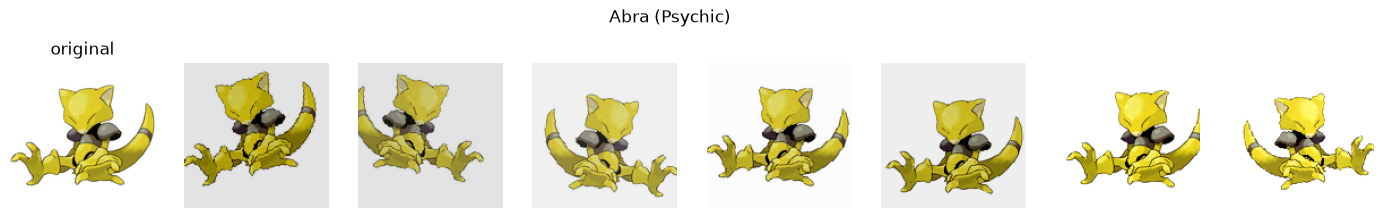

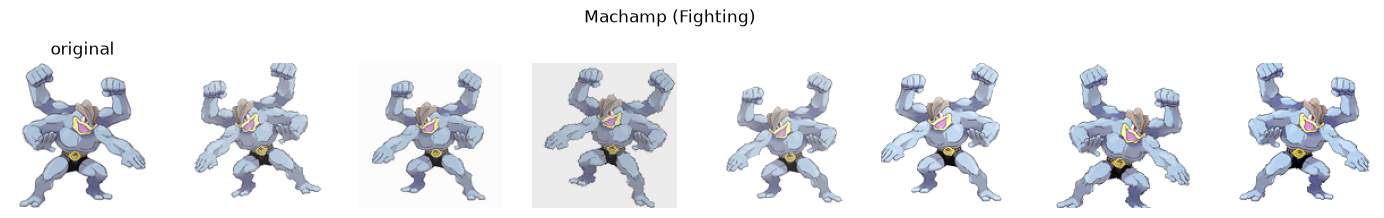

torch.Size([32, 3, 128, 128]) torch.float32 tensor([12,  3, 12,  6, 12, 17, 11,  3])


In [31]:
import matplotlib.pyplot as plt
import numpy as np

def show_augmentations(df, idx=0, n=7):
    row = df.iloc[idx]
    img = Image.open(row["image_path"]).convert("RGB")
    aug = v2.Compose(aug_steps)
    fig, axes = plt.subplots(1, n + 1, figsize=(2.2 * (n + 1), 2.6))
    axes[0].imshow(img); axes[0].set_title("original")
    for ax in axes[1:]:
        ax.imshow(aug(img))
    for ax in axes: ax.axis("off")
    plt.suptitle(f'{row["Pokemon"]} ({row["type1"]})')
    plt.show()

show_augmentations(train_df, idx=0)
show_augmentations(train_df, idx=len(train_df) // 2)

# Sanity-check a batch
xb, yb = next(iter(train_loader))
print(xb.shape, xb.dtype, yb[:8])

****

## Transfer Learning Investigation
In this section your team will investigate modern pretrained models. Choose two architectures from convolutional models developed in recent years, such as:
- EfficientNet
- MobileNetV3
- ConvNeXt
- DenseNet
- ResNet
- ConvNeXtV2
- RegNet

For each architecture investigate two training strategies

1) frozen feature extractor
2) partial/full fine tuning

Alternatively, you can instead investigate

1) different learning-rate schedules
2) different optimizers

This should result in four trained models. LLM assistance is permitted assuming that teams validate all generated code, identify at least one incorrect or inefficient LLM suggestion, and explain all experimental choices in their own words.

Chosen pretrained models:

1) EfficientNet
2) DenseNet

**Prompt:** I want to investigate two modern pre-trained models, EfficientNet and DenseNet. For each architecture, I want to investigate two training strategies, one is frozen feature extractor and the other is partial/full fine tuning. Please investigate each strategy for both architectures. 

**Agent used:** Claude Sonnet 5.5

**Output:**

# Transfer learning: EfficientNet-B0 and DenseNet-121, frozen vs. fine-tuned

This code assumes the `train_loader`, `val_loader`, `test_loader`, `train_df` and `TYPE_COLS` from the augmentation cell are defined. I haven't run it on your data, so treat the epoch counts and learning rates as starting points.

I picked EfficientNet-B0 and DenseNet-121 because they're the smallest standard variants. That suits your compute goal and the 1,170-image dataset.

## 1. Setup, model builder, and training loop

```python
import time, copy
import numpy as np
import torch, torch.nn as nn
import torchvision.models as tvm
from sklearn.metrics import f1_score

device = "cuda" if torch.cuda.is_available() else "cpu"
NUM_CLASSES = len(TYPE_COLS)   # 18
print("Device:", device)

# Class-weighted loss to counter imbalance (Flying has only 10 images overall)
counts = train_df["type1"].value_counts().reindex(TYPE_COLS).fillna(1).values
class_weights = torch.tensor(counts.sum() / (NUM_CLASSES * counts), dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)

def build_model(arch, strategy):
    """arch: 'efficientnet' | 'densenet'; strategy: 'frozen' | 'finetune'"""
    if arch == "efficientnet":
        model = tvm.efficientnet_b0(weights=tvm.EfficientNet_B0_Weights.IMAGENET1K_V1)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
        head_params = list(model.classifier.parameters())
        # partial fine-tune: last 3 of the 9 feature blocks
        unfreeze = [model.features[i] for i in (6, 7, 8)]
    else:
        model = tvm.densenet121(weights=tvm.DenseNet121_Weights.IMAGENET1K_V1)
        model.classifier = nn.Linear(model.classifier.in_features, NUM_CLASSES)
        head_params = list(model.classifier.parameters())
        # partial fine-tune: last dense block + final batch norm
        unfreeze = [model.features.denseblock4, model.features.norm5]

    # Freeze the whole backbone, then re-enable what the strategy needs
    for p in model.parameters():
        p.requires_grad = False
    for p in head_params:
        p.requires_grad = True
    backbone_params = []
    if strategy == "finetune":
        for block in unfreeze:
            for p in block.parameters():
                p.requires_grad = True
                backbone_params.append(p)
    return model.to(device), head_params, backbone_params

def keep_frozen_bn_in_eval(model):
    # Frozen layers should keep their ImageNet BatchNorm statistics,
    # otherwise train() mode updates them on our tiny dataset.
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d) and not any(p.requires_grad for p in m.parameters()):
            m.eval()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    all_logits, all_y, loss_sum = [], [], 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        loss_sum += criterion(out, y).item() * len(y)
        all_logits.append(out.cpu()); all_y.append(y.cpu())
    logits, y = torch.cat(all_logits), torch.cat(all_y)
    preds = logits.argmax(1)
    top3 = (logits.topk(3, dim=1).indices == y[:, None]).any(1).float().mean().item()
    return {
        "loss": loss_sum / len(y),
        "acc": (preds == y).float().mean().item(),
        "macro_f1": f1_score(y, preds, average="macro", labels=range(NUM_CLASSES), zero_division=0),
        "top3": top3,
        "preds": preds.numpy(), "y": y.numpy(), "logits": logits,
    }

def train_model(arch, strategy, epochs=20, head_lr=1e-3, backbone_lr=1e-4,
                weight_decay=1e-4, patience=5):
    model, head_params, backbone_params = build_model(arch, strategy)
    groups = [{"params": head_params, "lr": head_lr}]
    if backbone_params:
        groups.append({"params": backbone_params, "lr": backbone_lr})
    optimizer = torch.optim.AdamW(groups, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_total = sum(p.numel() for p in model.parameters())
    print(f"{arch}/{strategy}: {n_trainable:,} trainable of {n_total:,} parameters")

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_macro_f1": []}
    best_f1, best_state, bad_epochs = -1, None, 0
    start = time.time()

    for epoch in range(epochs):
        model.train()
        keep_frozen_bn_in_eval(model)
        loss_sum, correct, n = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)
        scheduler.step()

        val = evaluate(model, val_loader)
        history["train_loss"].append(loss_sum / n); history["train_acc"].append(correct / n)
        history["val_loss"].append(val["loss"]); history["val_acc"].append(val["acc"])
        history["val_macro_f1"].append(val["macro_f1"])
        print(f"epoch {epoch+1:2d} | train loss {loss_sum/n:.3f} acc {correct/n:.3f} | "
              f"val loss {val['loss']:.3f} acc {val['acc']:.3f} macro-F1 {val['macro_f1']:.3f}")

        # Validation macro-F1 selects the checkpoint and drives early stopping
        if val["macro_f1"] > best_f1:
            best_f1, best_state, bad_epochs = val["macro_f1"], copy.deepcopy(model.state_dict()), 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f"Early stopping at epoch {epoch+1}"); break

    train_time = time.time() - start
    model.load_state_dict(best_state)
    return model, {"history": history, "best_val_macro_f1": best_f1,
                   "train_time_s": train_time, "trainable_params": n_trainable}
```

## 2. Train the four models

```python
results, models = {}, {}
for arch in ["efficientnet", "densenet"]:
    for strategy in ["frozen", "finetune"]:
        key = f"{arch}_{strategy}"
        models[key], results[key] = train_model(arch, strategy)
        torch.save(models[key].state_dict(), f"{key}.pt")
```

If you run out of memory, drop the batch size to 16 in the loaders. DenseNet is the more memory-hungry model.

## 3. Compare training curves

```python
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=False)
for ax, key in zip(axes.ravel(), results):
    h = results[key]["history"]
    ax.plot(h["train_loss"], label="train loss")
    ax.plot(h["val_loss"], label="val loss")
    ax.plot(h["val_macro_f1"], label="val macro-F1", linestyle="--")
    ax.set_title(key); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.show()
```

## 4. Validation summary

Keep the test set untouched until the Comparative Evaluation section.

```python
import pandas as pd
summary = pd.DataFrame({
    k: {"best val macro-F1": v["best_val_macro_f1"],
        "epochs run": len(v["history"]["val_loss"]),
        "trainable params": v["trainable_params"],
        "train time (s)": round(v["train_time_s"], 1)}
    for k, v in results.items()
}).T
display(summary)
```

## What the strategies do (draft for your notebook)

| Strategy | EfficientNet-B0 | DenseNet-121 |
|---|---|---|
| Frozen feature extractor | Only the new linear classifier trains. | Only the new linear classifier trains. |
| Partial fine-tune | Feature blocks 6–8 plus the classifier, with backbone LR 1e-4 against head LR 1e-3. | `denseblock4`, `norm5` and the classifier, with the same LR split. |

- **Why partial rather than full fine-tuning:** with about 800 training images, unfreezing everything risks overfitting and erasing the useful ImageNet features. Early layers hold generic edges and textures, while later layers are more task-specific.
- **Why a lower backbone LR:** pretrained weights need small adjustments, while the randomly initialized head needs larger ones.
- **Why macro-F1 for checkpointing:** it matches the metric chosen in your Evaluation Strategy section. Plain accuracy would favor Water and Normal.

## Candidate "incorrect or inefficient suggestion" for your report

Write your own justification, but here are real pitfalls to check:

- **BatchNorm in frozen layers.** The default `model.train()` updates BatchNorm statistics even when weights are frozen. With small, imbalanced batches this slowly corrupts the pretrained statistics, which is why `keep_frozen_bn_in_eval` exists. Verify that it makes a difference by running a frozen model without it.
- **Fine-tuning everything at one learning rate** is a common default and usually a poor one here.
- **Training at 128×128.** These models were trained at 224×224, so there is a resolution mismatch. It's cheap, but you could test `v2.Resize(224)` as an ablation.

## Caveats

- With a 10-image Flying class and a roughly 100-image validation set, per-class metrics and macro-F1 will be noisy. Run each model with a couple of seeds if time allows.
- `random_state` isn't set for PyTorch here. Add `torch.manual_seed(42)` at the top for reproducibility, since the lab requires reproducible results.
- The learning rates, epoch count and patience are untuned. Your Hyperparameter Investigation section is where you vary them.
- The `train_loader` doesn't use the class-balancing sampler, so the weighted loss is the only imbalance handling here.

When you've run it, send me the summary table and I can help interpret the results or pick which model to use for the hyperparameter investigation.

In [33]:
# Pretrained model 1a

# Setup, model builder, and training loop
import time, copy
import numpy as np
import torch, torch.nn as nn
import torchvision.models as tvm
from sklearn.metrics import f1_score

device = "cuda" if torch.cuda.is_available() else "cpu"
NUM_CLASSES = len(TYPE_COLS)   # 18
print("Device:", device)

# Class-weighted loss to counter imbalance (Flying has only 10 images overall)
counts = train_df["type1"].value_counts().reindex(TYPE_COLS).fillna(1).values
class_weights = torch.tensor(counts.sum() / (NUM_CLASSES * counts), dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)

def build_model(arch, strategy):
    """arch: 'efficientnet' | 'densenet'; strategy: 'frozen' | 'finetune'"""
    if arch == "efficientnet":
        model = tvm.efficientnet_b0(weights=tvm.EfficientNet_B0_Weights.IMAGENET1K_V1)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
        head_params = list(model.classifier.parameters())
        # partial fine-tune: last 3 of the 9 feature blocks
        unfreeze = [model.features[i] for i in (6, 7, 8)]
    else:
        model = tvm.densenet121(weights=tvm.DenseNet121_Weights.IMAGENET1K_V1)
        model.classifier = nn.Linear(model.classifier.in_features, NUM_CLASSES)
        head_params = list(model.classifier.parameters())
        # partial fine-tune: last dense block + final batch norm
        unfreeze = [model.features.denseblock4, model.features.norm5]

    # Freeze the whole backbone, then re-enable what the strategy needs
    for p in model.parameters():
        p.requires_grad = False
    for p in head_params:
        p.requires_grad = True
    backbone_params = []
    if strategy == "finetune":
        for block in unfreeze:
            for p in block.parameters():
                p.requires_grad = True
                backbone_params.append(p)
    return model.to(device), head_params, backbone_params

def keep_frozen_bn_in_eval(model):
    # Frozen layers should keep their ImageNet BatchNorm statistics,
    # otherwise train() mode updates them on our tiny dataset.
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d) and not any(p.requires_grad for p in m.parameters()):
            m.eval()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    all_logits, all_y, loss_sum = [], [], 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        loss_sum += criterion(out, y).item() * len(y)
        all_logits.append(out.cpu()); all_y.append(y.cpu())
    logits, y = torch.cat(all_logits), torch.cat(all_y)
    preds = logits.argmax(1)
    top3 = (logits.topk(3, dim=1).indices == y[:, None]).any(1).float().mean().item()
    return {
        "loss": loss_sum / len(y),
        "acc": (preds == y).float().mean().item(),
        "macro_f1": f1_score(y, preds, average="macro", labels=range(NUM_CLASSES), zero_division=0),
        "top3": top3,
        "preds": preds.numpy(), "y": y.numpy(), "logits": logits,
    }

def train_model(arch, strategy, epochs=20, head_lr=1e-3, backbone_lr=1e-4,
                weight_decay=1e-4, patience=5):
    model, head_params, backbone_params = build_model(arch, strategy)
    groups = [{"params": head_params, "lr": head_lr}]
    if backbone_params:
        groups.append({"params": backbone_params, "lr": backbone_lr})
    optimizer = torch.optim.AdamW(groups, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_total = sum(p.numel() for p in model.parameters())
    print(f"{arch}/{strategy}: {n_trainable:,} trainable of {n_total:,} parameters")

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_macro_f1": []}
    best_f1, best_state, bad_epochs = -1, None, 0
    start = time.time()

    for epoch in range(epochs):
        model.train()
        keep_frozen_bn_in_eval(model)
        loss_sum, correct, n = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)
        scheduler.step()

        val = evaluate(model, val_loader)
        history["train_loss"].append(loss_sum / n); history["train_acc"].append(correct / n)
        history["val_loss"].append(val["loss"]); history["val_acc"].append(val["acc"])
        history["val_macro_f1"].append(val["macro_f1"])
        print(f"epoch {epoch+1:2d} | train loss {loss_sum/n:.3f} acc {correct/n:.3f} | "
              f"val loss {val['loss']:.3f} acc {val['acc']:.3f} macro-F1 {val['macro_f1']:.3f}")

        # Validation macro-F1 selects the checkpoint and drives early stopping
        if val["macro_f1"] > best_f1:
            best_f1, best_state, bad_epochs = val["macro_f1"], copy.deepcopy(model.state_dict()), 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f"Early stopping at epoch {epoch+1}"); break

    train_time = time.time() - start
    model.load_state_dict(best_state)
    return model, {"history": history, "best_val_macro_f1": best_f1,
                   "train_time_s": train_time, "trainable_params": n_trainable}

Device: cpu


In [ ]:
# Train the four models
results, models = {}, {}
for arch in ["efficientnet", "densenet"]:
    for strategy in ["frozen", "finetune"]:
        key = f"{arch}_{strategy}"
        models[key], results[key] = train_model(arch, strategy)
        torch.save(models[key].state_dict(), f"{key}.pt")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\lucyp/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:01<00:00, 12.1MB/s]


efficientnet/frozen: 23,058 trainable of 4,030,606 parameters
epoch  1 | train loss 2.847 acc 0.115 | val loss 2.684 acc 0.172 macro-F1 0.158
epoch  2 | train loss 2.508 acc 0.288 | val loss 2.519 acc 0.276 macro-F1 0.278
epoch  3 | train loss 2.279 acc 0.359 | val loss 2.417 acc 0.259 macro-F1 0.265
epoch  4 | train loss 2.116 acc 0.393 | val loss 2.353 acc 0.284 macro-F1 0.283
epoch  5 | train loss 2.000 acc 0.438 | val loss 2.313 acc 0.276 macro-F1 0.271
epoch  6 | train loss 1.870 acc 0.494 | val loss 2.298 acc 0.293 macro-F1 0.283
epoch  7 | train loss 1.825 acc 0.496 | val loss 2.289 acc 0.293 macro-F1 0.287
epoch  8 | train loss 1.737 acc 0.512 | val loss 2.270 acc 0.319 macro-F1 0.276
epoch  9 | train loss 1.681 acc 0.529 | val loss 2.264 acc 0.293 macro-F1 0.255
epoch 10 | train loss 1.643 acc 0.551 | val loss 2.239 acc 0.319 macro-F1 0.308
epoch 11 | train loss 1.607 acc 0.537 | val loss 2.246 acc 0.302 macro-F1 0.254
epoch 12 | train loss 1.508 acc 0.599 | val loss 2.234 acc

In [ ]:
# Compare training curves
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=False)
for ax, key in zip(axes.ravel(), results):
    h = results[key]["history"]
    ax.plot(h["train_loss"], label="train loss")
    ax.plot(h["val_loss"], label="val loss")
    ax.plot(h["val_macro_f1"], label="val macro-F1", linestyle="--")
    ax.set_title(key); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.show()

In [ ]:
# Validation summary
import pandas as pd
summary = pd.DataFrame({
    k: {"best val macro-F1": v["best_val_macro_f1"],
        "epochs run": len(v["history"]["val_loss"]),
        "trainable params": v["trainable_params"],
        "train time (s)": round(v["train_time_s"], 1)}
    for k, v in results.items()
}).T
display(summary)

****

## Hyperparameter Investigation
For one of the trained models, investigate at least two parameters from the following list:
- learning rate
- optimizer
- batch size
- dropout
- early stopping
- learning-rate scheduling

Visualize training and validation performance for each configuration. Use the best parameters to train the remaining three models. Discuss convergence and overfitting. LLM-generated experimentation code is allowed but must be validated.

****

## Comparative Evaluation
Compare all trained models using the evaluation metric selected earlier. Use statistical comparisons where appropriate. Include quantitative comparisons, confusion matrices, representative classification successes and failures, and discussion of computational cost. If an LLM assists with interpretation, identify one useful observation, one incorrect or unsupported conclusion, and provide your final interpretation.

****

## Exceptional Work
Provide additional analysis extending your investigation.

**Exceptional work topic (potentially):**
- Since a Pokemon's color palette tend to match with its typing, say we converted the images to grayscale format and used exclusively the grayscale images to train a new model. Would it still be able to recognize features that differentiate Pokemon types as well as the model we made?
- If we found a dataset with information that quantifies how popular a Pokemon is, would we be able to identify designs features that appeal the most to audiences?